# Credit Card Fraud Detection

**Dataset:** ULB Credit Card Fraud — 284,807 real (anonymised) European card transactions over two days in September 2013, of which just 492 (0.17%) are fraud. Features V1–V28 are PCA components published by the researchers; only `Time` and `Amount` are raw.

**The honest problem:** a model that says 'legitimate' to everything scores 99.83% accuracy and catches **zero** fraud. So this project is judged on fraud recall, precision and PR-AUC — not accuracy.

In [1]:
import io, urllib.request
import pandas as pd

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

d = pd.read_csv(io.BytesIO(get('https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv')))
print(d.shape)
d.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
print('Fraud share:', round(100 * d['Class'].mean(), 3), '%')
print('Fraud count:', int(d['Class'].sum()), 'of', len(d))

Fraud share: 0.173 %
Fraud count: 492 of 284807


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = d.drop(columns=['Class']); y = d['Class'].astype(int)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr)

Accuracy (misleading here): 0.9768
Always-legit baseline accuracy: 0.9983
ROC-AUC: 0.9726
PR-AUC (average precision): 0.7039
              precision    recall  f1-score   support

       Legit       1.00      0.98      0.99     71079
       Fraud       0.06      0.89      0.12       123

    accuracy                           0.98     71202
   macro avg       0.53      0.93      0.55     71202
weighted avg       1.00      0.98      0.99     71202



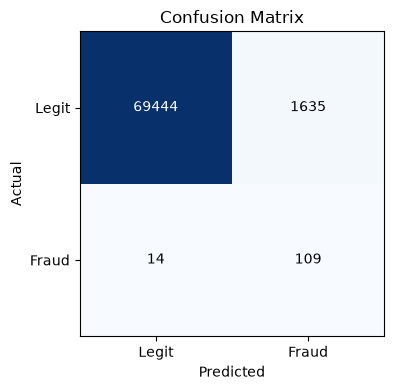

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, average_precision_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt

# class_weight='balanced' makes the rare fraud class count — essential here
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(sc.transform(Xtr), ytr)
pred = lr.predict(sc.transform(Xte)); prob = lr.predict_proba(sc.transform(Xte))[:, 1]
print('Accuracy (misleading here):', round(accuracy_score(yte, pred), 4))
print('Always-legit baseline accuracy:', round(float((yte == 0).mean()), 4))
print('ROC-AUC:', round(roc_auc_score(yte, prob), 4))
print('PR-AUC (average precision):', round(average_precision_score(yte, prob), 4))
print(classification_report(yte, pred, target_names=['Legit', 'Fraud']))
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['Legit', 'Fraud']); ax.set_yticks([0, 1], ['Legit', 'Fraud'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- On imbalanced data, **accuracy is a trap**: the baseline that catches nothing scores 99.83%.
- `class_weight='balanced'` trades a flood of false alarms for actually catching fraud — the right trade when a missed fraud costs far more than a reviewed transaction.
- PR-AUC is the honest headline metric at 0.17% prevalence; ROC-AUC flatters because true negatives dominate.